# 강아지·고양이 분류 프로젝트

- Dataset : 고양이 0 / 강아지 1, RGB 64×64, 픽셀 순서 `(채널, 높이, 너비)`

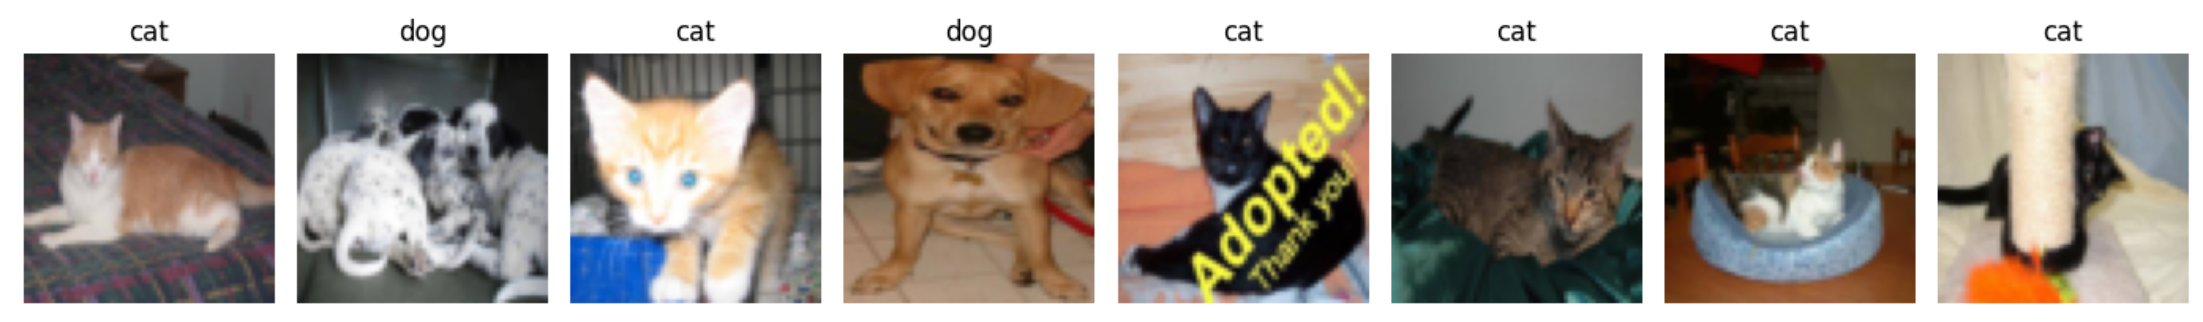


- Colab GPU를 사용하세요.
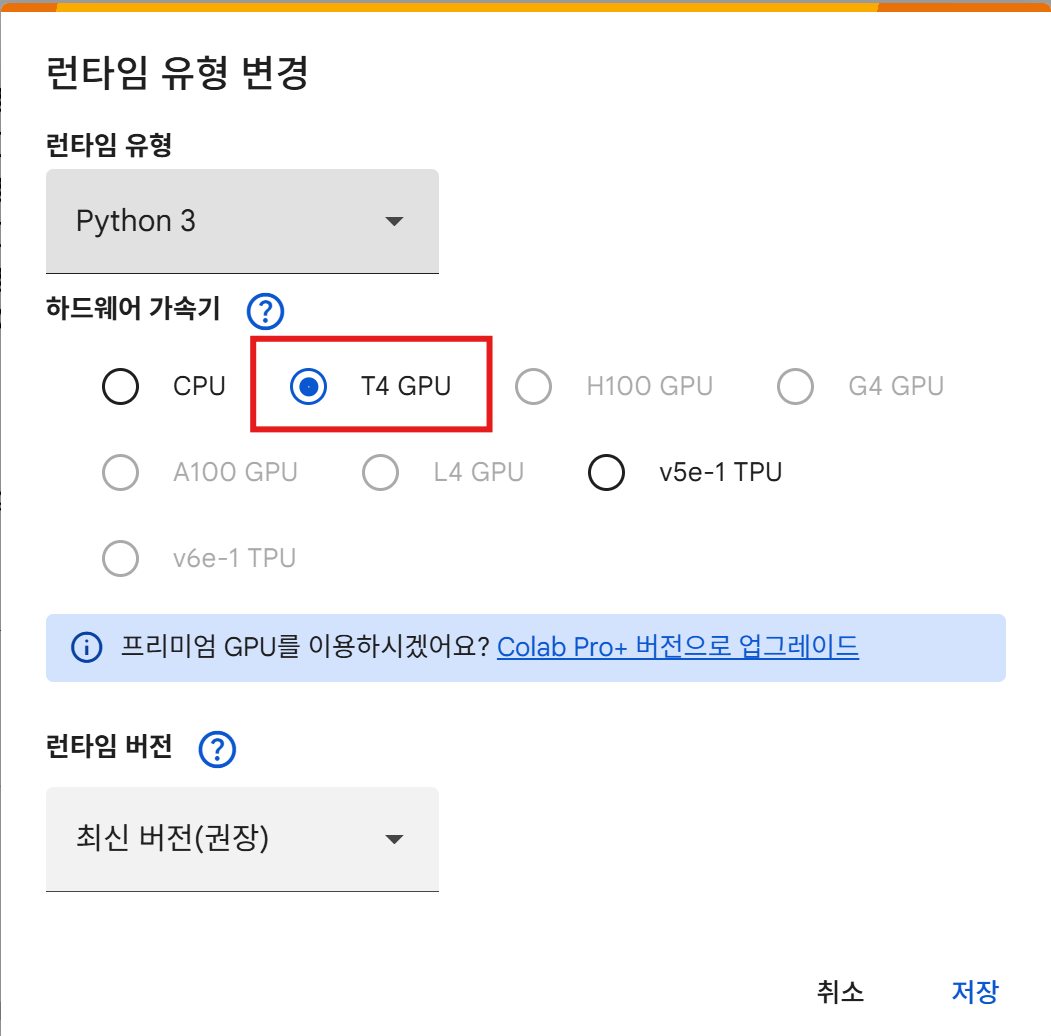
- 실제 채점사이트 업로드는 생성된 output.csv를 다운로드한 뒤 직접 진행하세요.

## 데이터 준비 — 패키지와 실행 환경

In [20]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classes = ["고양이", "강아지"]
print("device:", device)


device: cuda


## 데이터 준비 — GitHub에서 불러오기


In [21]:
#데이터 다운로드
base_url = "https://raw.githubusercontent.com/yeonbinkang/cat_dog_classification_dataset/main/"
file_list = pd.read_csv(base_url + "file_list.csv")
df = pd.concat([
    pd.read_csv(base_url + filename, compression="gzip")
    for filename in file_list["filename"]], ignore_index=True)

assert list(df.columns) == ["pixels", "label"]
assert df["label"].isin([0, 1]).all()
print("전체 데이터:", df.shape)
display(df.head())


전체 데이터: (9928, 2)


,pixels,label
0,"[27,31,31,30,30,32,39,29,31,33,33,38,38,45,50,...",0
1,"[24,21,19,19,18,18,28,25,21,23,25,28,28,27,27,...",1
2,"[35,36,38,38,38,43,60,65,65,62,41,60,61,40,46,...",0
3,"[30,30,30,28,28,27,28,27,26,25,25,26,24,23,22,...",1
4,"[193,195,197,197,197,198,198,199,200,202,197,1...",0


## 데이터 준비 — Tensor와 DataLoader
전체 데이터를 살펴보기 위한 `preview_loader`입니다. 실제 학습에는 4단계에서 만드는 `trainloader`만 사용하세요.

In [22]:
pixels = np.array(df["pixels"].map(json.loads).tolist(), dtype=np.uint8)
X = torch.tensor(pixels, dtype=torch.float32)
X = X.reshape(-1, 3, 64, 64)
X = (X / 255 - 0.5) / 0.5

y = torch.tensor(df["label"].to_numpy(), dtype=torch.long)

preview_dataset = TensorDataset(X, y)
preview_loader = DataLoader(preview_dataset, batch_size=32, shuffle=False)


## 한 배치만 확인해보기
시각화할 때는 (-1,1)로 정규화된 값을 다시 (0,1)로 복원합니다.

한 배치 이미지: torch.Size([32, 3, 64, 64])
한 배치 정답: torch.Size([32])


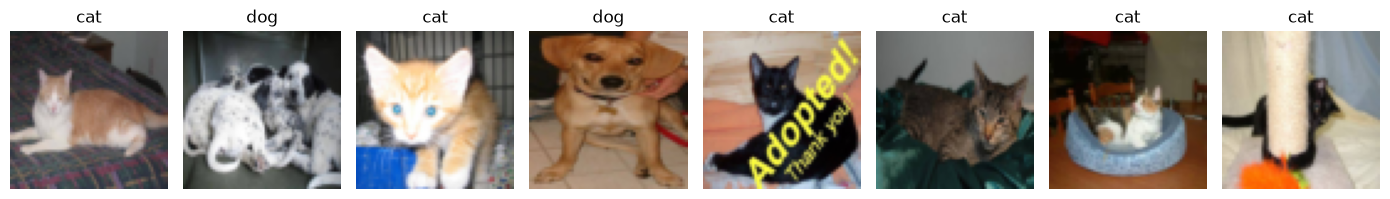

In [23]:
images, labels = next(iter(preview_loader))
print("한 배치 이미지:", images.shape)
print("한 배치 정답:", labels.shape)

fig, axes = plt.subplots(1, 8, figsize=(14, 3))
for i, ax in enumerate(axes):
    image = (images[i] * 0.5 + 0.5).permute(1, 2, 0)
    ax.imshow(image.numpy())
    ax.set_title(["cat", "dog"][labels[i].item()])
    ax.axis("off")
plt.tight_layout()
plt.show()


## 1) shape을 확인합니다.

`df`, `X`, `y`의 shape을 출력하고 각 차원이 무엇을 뜻하는지 설명하세요.

- DataFrame: `(이미지 수, 2)` — pixels(JSON 리스트 문자열) + label
- 입력 Tensor: `(이미지 수, 3, 64, 64)`
- 정답 Tensor: `(이미지 수,)`


In [24]:
print("df:", df.shape)
print("X:", X.shape)
print("y:", y.shape)


df: (9928, 2)
X: torch.Size([9928, 3, 64, 64])
y: torch.Size([9928])


## 2) tensor로 변환합니다.

앞의 준비 코드를 참고해 `X`, `y`를 직접 다시 만들어보세요. 반드시 **df의 원본 픽셀값에서 시작**합니다.

1. `df["pixels"].map(json.loads).tolist()`로 JSON 문자열을 리스트로 복원하고 NumPy 배열을 거쳐 `torch.float32` Tensor로 변환합니다.
2. 입력을 `(-1, 3, 64, 64)`로 reshape합니다.
3. 입력을 255로 나눈 뒤 `(X - 0.5) / 0.5`로 정규화합니다.
4. `label` 열을 `torch.long` Tensor로 변환합니다.

CrossEntropyLoss를 사용할 때 정답은 정수 클래스 번호여야 합니다.


In [25]:
# df의 원본 픽셀값에서 변환하므로 중복 정규화하지 않습니다.
pixels = np.array(df["pixels"].map(json.loads).tolist(), dtype=np.uint8)
assert pixels.shape == (len(df), 12288)
X = torch.tensor(pixels, dtype=torch.float32).reshape(-1, 3, 64, 64)
X = (X / 255 - 0.5) / 0.5
y = torch.tensor(df["label"].to_numpy(), dtype=torch.long)
print("X:", X.shape, X.dtype)
print("y:", y.shape, y.dtype)


X: torch.Size([9928, 3, 64, 64]) torch.float32
y: torch.Size([9928]) torch.int64


## 3) 모델 class를 구성합니다.

`nn.Module`을 상속하여 `CNN` 클래스를 구현하세요. 아래는 간단한 구조 예시입니다. 레이어 수, 채널 수, 활성화 함수 등을 바꾸어도 됩니다.

```python
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(16 * 32 * 32, 2)
        )

    def forward(self, x):
        return self.layers(x)
```

입력 shape은 `(batch_size, 3, 64, 64)`, 출력 shape은 `(batch_size, 2)`입니다.
CrossEntropyLoss를 사용할 경우 마지막에 Softmax를 붙이지 않습니다.


In [26]:
import torch
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        
        # Convolution 채널 확장 및 Sequential 적용
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 64 -> 32
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 32 -> 16
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 16 -> 8
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)  # 8 -> 4 (64x64 입력 기준 최종 4x4)
        )
        
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

**신경망 인스턴스를 생성하고 출력하여 레이어 상태를 확인하자.**

- 신경망 모델을 device로 옮기는것을 잊지 말자.

In [27]:
model = CNN().to(device)

## 4) train, test를 분리합니다.

`train_test_split`으로 **인덱스를 분리**한 뒤, 해당 인덱스로 X와 y를 함께 선택하세요. `stratify`는 두 클래스의 비율을 유지합니다.

```python
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y.numpy()
)

train_dataset = TensorDataset(X[train_idx], y[train_idx])
test_dataset = TensorDataset(X[test_idx], y[test_idx])

trainloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
testloader = DataLoader(test_dataset, batch_size=64, shuffle=False)
```

학습에는 train만 사용하고, test는 최종 평가에 사용하세요. 모델이나 설정을 비교하려면 train에서 validation을 추가로 분리하세요.


In [28]:
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=42, stratify=y.numpy()
)

train_dataset = TensorDataset(X[train_idx], y[train_idx])
test_dataset = TensorDataset(X[test_idx], y[test_idx])

trainloader = DataLoader(train_dataset,
                         batch_size=64,
                         shuffle=True)

testloader = DataLoader(test_dataset,
                        batch_size=64,
                        shuffle=False)

assert set(train_idx).isdisjoint(test_idx)
print("train:", len(train_dataset), "/ test:", len(test_dataset))


train: 7942 / test: 1986


## 5) 학습

손실함수, optimizer, epoch 수를 선택하고 학습 코드를 작성하세요.

각 epoch에서 `model.train()`을 호출하고, 배치마다 아래 순서로 학습합니다.

1. 입력과 정답을 device로 이동
2. gradient 초기화
3. 순전파 → loss 계산
4. 역전파 → 가중치 업데이트

loss 그래프는 미리 작성되어 있습니다. **epoch마다 평균 loss를 `train_losses`에 추가**하세요.

```python
# epoch 시작 시
running_loss = 0.0

# 각 배치의 학습이 끝난 뒤
running_loss += loss.item() * X_batch.size(0)

# epoch 종료 시
avg_loss = running_loss / len(trainloader.dataset)
train_losses.append(avg_loss)
```


In [29]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

epochs = 30

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=epochs,
    eta_min=1e-6
)

train_losses = []
train_accuracies = []


In [30]:
for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in trainloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()

        # 큰 기울기로 인한 불안정한 업데이트 완화
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        running_loss += loss.item() * y_batch.size(0)
        correct += (
            outputs.argmax(dim=1) == y_batch
        ).sum().item()
        total += y_batch.size(0)

    avg_loss = running_loss / total
    train_acc = correct / total

    train_losses.append(avg_loss)
    train_accuracies.append(train_acc)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Train accuracy: {train_acc:.2%} | "
        f"LR: {optimizer.param_groups[0]['lr']:.7f}"
    )

    scheduler.step()

torch.save(model.state_dict(), "cat_dog_model.pth")
print("모델 저장 완료: cat_dog_model.pth")

Epoch 01/30 | Loss: 0.6345 | Train accuracy: 64.23% | LR: 0.0003000
Epoch 02/30 | Loss: 0.5460 | Train accuracy: 72.49% | LR: 0.0002992
Epoch 03/30 | Loss: 0.5002 | Train accuracy: 75.96% | LR: 0.0002967
Epoch 04/30 | Loss: 0.4521 | Train accuracy: 79.21% | LR: 0.0002927
Epoch 05/30 | Loss: 0.4091 | Train accuracy: 81.55% | LR: 0.0002871
Epoch 06/30 | Loss: 0.3819 | Train accuracy: 83.27% | LR: 0.0002800
Epoch 07/30 | Loss: 0.3450 | Train accuracy: 85.03% | LR: 0.0002714
Epoch 08/30 | Loss: 0.3154 | Train accuracy: 86.58% | LR: 0.0002616
Epoch 09/30 | Loss: 0.2894 | Train accuracy: 87.95% | LR: 0.0002505
Epoch 10/30 | Loss: 0.2762 | Train accuracy: 88.25% | LR: 0.0002384
Epoch 11/30 | Loss: 0.2426 | Train accuracy: 90.03% | LR: 0.0002252
Epoch 12/30 | Loss: 0.2114 | Train accuracy: 91.45% | LR: 0.0002113
Epoch 13/30 | Loss: 0.1835 | Train accuracy: 92.67% | LR: 0.0001967
Epoch 14/30 | Loss: 0.1621 | Train accuracy: 93.94% | LR: 0.0001816
Epoch 15/30 | Loss: 0.1405 | Train accuracy: 95.

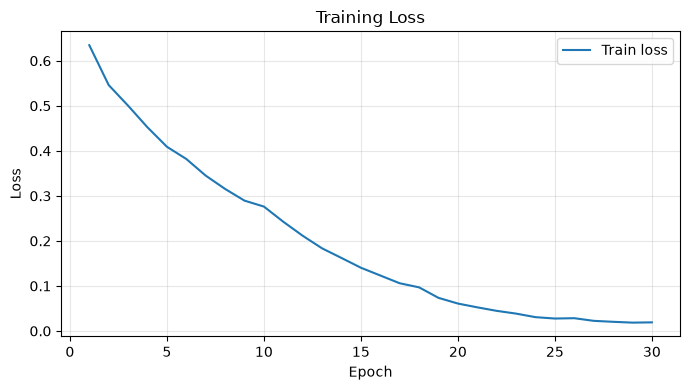

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Train loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6) 테스트

`testloader`로 정확도를 계산하세요.

- `model.eval()`로 평가 모드로 전환합니다.
- `with torch.no_grad():` 안에서 예측합니다.
- `outputs.argmax(dim=1)`로 예측 클래스를 구합니다.
- 정답과 일치하는 개수를 누적하여 전체 개수로 나눕니다.
- 테스트 데이터로 역전파하거나 optimizer를 업데이트하지 않습니다.


In [32]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for X_batch, y_batch in testloader:
        outputs = model(X_batch.to(device))
        predictions = outputs.argmax(dim=1).cpu()
        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)
print(f"test accuracy: {correct / total * 100:.2f}% ({correct}/{total})")

test accuracy: 83.89% (1666/1986)


## 7) 채점사이트에 제출하기

채점사이트에서 제공하는 **input.csv**를 Colab에 업로드하세요. 아래 코드는 완성된 `model`로 예측하고 **output.csv**를 저장하는 예시입니다.

- 학습 때와 동일하게 reshape·정규화합니다.
- **입력 행 순서를 유지**해야 하므로 `shuffle=False`로 설정합니다.
- 제출 파일은 `label` 열 하나, 각 행은 정수 0 또는 1입니다.
- `index=False`를 사용해 인덱스 열을 제외합니다.
- 확장자는 `.csv`입니다. 정답 파일이나 이미지 경로는 제출하지 않습니다.


In [33]:
from pathlib import Path

# VS Code에서는 현재 작업 폴더 기준입니다.
# 파일을 찾지 못하면 절대 경로로 변경하세요.
input_path = Path("input.csv")
print("현재 작업 폴더:", Path.cwd())

sub = pd.read_csv(input_path)

# 원본 데이터의 픽셀 순서는 CHW입니다.
X_sub_np = np.asarray(
    sub["pixels"].map(json.loads).tolist(),
    dtype=np.float32
)

assert X_sub_np.shape == (len(sub), 3 * 64 * 64)
assert np.isfinite(X_sub_np).all()
assert X_sub_np.min() >= 0 and X_sub_np.max() <= 255

X_sub = torch.from_numpy(
    X_sub_np.reshape(-1, 3, 64, 64)
)

# 반드시 학습 데이터와 같은 정규화 적용
X_sub = (X_sub / 255.0 - 0.5) / 0.5

sub_loader = DataLoader(
    X_sub,
    batch_size=64,
    shuffle=False
)

model.eval()
predictions = []

with torch.inference_mode():
    for X_batch in sub_loader:
        outputs = model(X_batch.to(device))
        predictions.extend(
            outputs.argmax(dim=1).cpu().tolist()
        )

submission = pd.DataFrame({
    "label": predictions
})

output_path = Path("output.csv")
submission.to_csv(output_path, index=False)

assert len(submission) == len(sub)
assert submission["label"].isin([0, 1]).all()

print("저장 위치:", output_path.resolve())
print("예측 이미지 수:", len(submission))
display(submission.head())

# 정답이 포함된 입력 파일에서만 정확도 계산 가능
if "label" in sub.columns:
    assert sub["label"].isin([0, 1]).all()

    accuracy = (
        np.asarray(predictions) == sub["label"].to_numpy()
    ).mean()

    print(f"Input accuracy: {accuracy:.2%}")
else:
    print(
        "input.csv에 정답 label이 없어 정확도를 계산할 수 없습니다. "
        "output.csv를 채점사이트에 제출하세요."
    )

현재 작업 폴더: c:\Users\user\Desktop\DL\3일차
저장 위치: C:\Users\user\Desktop\DL\3일차\output.csv
예측 이미지 수: 100


,label
0,0
1,0
2,1
3,1
4,1


input.csv에 정답 label이 없어 정확도를 계산할 수 없습니다. output.csv를 채점사이트에 제출하세요.


In [34]:
# import io
# from google.colab import files

# # 채점사이트에 등록한 100행의 input.csv를 선택하세요.
# uploaded_input = files.upload()
# input_name = next(iter(uploaded_input))
# input_bytes = uploaded_input[input_name]


In [35]:
# grading_df = pd.read_csv(io.BytesIO(input_bytes))
# assert list(grading_df.columns) == ["pixels"], "JSON pixels 1열의 input.csv가 필요합니다."
# assert len(grading_df) == 100, "채점용 input.csv는 100행이어야 합니다."
# grading_pixels = np.array(grading_df["pixels"].map(json.loads).tolist())
# assert grading_pixels.shape == (100, 12288)
# assert grading_pixels.min() >= 0 and grading_pixels.max() <= 255
# X_grading = torch.tensor(grading_pixels, dtype=torch.float32).reshape(-1, 3, 64, 64)
# X_grading = (X_grading / 255 - 0.5) / 0.5

# grading_loader = DataLoader(TensorDataset(X_grading), batch_size=64, shuffle=False)
# model.eval()
# predictions = []
# with torch.no_grad():
#     for (X_batch,) in grading_loader:
#         outputs = model(X_batch.to(device))
#         predictions.extend(outputs.argmax(dim=1).cpu().tolist())

# submission = pd.DataFrame({"label": predictions})
# submission.to_csv("output.csv", index=False)

# # 파일을 다시 읽어 실제 제출 형식을 검사합니다.
# saved = pd.read_csv("output.csv")
# assert list(saved.columns) == ["label"]
# assert saved.shape == (100, 1)
# assert saved["label"].isin([0, 1]).all()
# assert pd.api.types.is_integer_dtype(saved["label"])
# assert saved["label"].tolist() == predictions
# print("제출 형식 검사 통과:", saved.shape)
# print(saved["label"].value_counts().sort_index())
# display(saved.head())


In [36]:
# files.download("output.csv")


다운로드한 **output.csv**를 채점사이트에 제출하세요. 채점용 100장이라면 헤더를 제외한 데이터 행은 100개여야 합니다.